# PSTL example (host + JAX, `model_jax`)

Point-source triple-lens photometry and astrometry from `bagle.model_jax`.
Compared to the matching binary-lens (`PSBL`) model with the same 1–2 pair
and `mLt = 0`.

Figures:
- unlensed source and three lens tracks,
- lensed image positions and magnifications,
- photometric light curve (PSTL vs PSBL),
- lensed astrometric centroid (PSTL vs PSBL),
- caustics and critical curves,
- inverse-ray-shoot magnification map.

**Units (phot+astrom):** `sep12` / `sep13` in mas; $\theta_E$ from $m_{Lp}+m_{Ls}$ only;
`m3` is added in $\mathrm{arcsec}^2$.

In [6]:
%matplotlib inline
from bagle import model_jax as model
from bagle import plot_models
import numpy as np
import matplotlib.pyplot as plt

<unknown>:5583: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:5799: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:6132: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:6352: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:5583: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:5799: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<unknown>:6132: Syntax

## Phot+astrom parameters

| Param | Value | Units |
|---|---|---|
| $m_{Lp}, m_{Ls}, m_{Lt}$ | 10, 5, 2 | $M_\odot$ |
| $t_0$ | 57000 | MJD |
| $\beta$ | 0.4 | mas |
| $sep_{12}, sep_{13}$ | 3.0, 2.0 | mas |
| $\alpha_{12}, \alpha_{13}$ | 90, 45 | deg |
| $d_L, d_S$ | 2000, 4000 | pc |
| $\mu_S$ | (4, −3) | mas/yr |
| $b_{sff}$ | 1.0 | |
| $mag_{src}$ | 18.0 | |

In [7]:
def build_pstl_psbl(mLt=2.0):
    """
    Build matching PSTL / PSBL PhotAstrom_noPar_Param1 models.

    Parameters
    ----------
    mLt : float
        Tertiary mass (Msun). The PSBL twin always has no third lens.

    Returns
    -------
    pstl, psbl
        Instantiated models.
    """
    shared = dict(
        mLp=10.0, mLs=5.0, t0=57000.0,
        xS0_E=np.array([0.0]), xS0_N=np.array([0.01]),
        beta=0.4, muL_E=0.0, muL_N=0.0,
        muS_E=4.0, muS_N=-3.0, dL=2000.0, dS=4000.0,
        b_sff=np.array([1.0]), mag_src=np.array([18.0]),
        dmag_Lp_Ls=np.array([20.0]), root_tol=1e-4)

    pstl = model.PSTL_PhotAstrom_noPar_Param1(
        mLt=mLt, sep12=3.0, sep13=2.0, alpha12=90.0, alpha13=45.0,
        **shared)
    psbl = model.PSBL_PhotAstrom_noPar_Param1(
        sep=3.0, alpha=90.0, **shared)
    return pstl, psbl


pstl, psbl = build_pstl_psbl(mLt=2.0)
pstl0, _ = build_pstl_psbl(mLt=0.0)
t = np.linspace(pstl.t0 - 200.0, pstl.t0 + 200.0, 241)
print('thetaE (pair, mas) =', pstl.thetaE_amp)
print('m1, m2, m3 (arcsec^2) =', pstl.m1, pstl.m2, pstl.m3)

thetaE (pair, mas) = 5.526250970390223
m1, m2, m3 (arcsec^2) = 2.0359633191825923e-05 1.0179816595912961e-05 4.071926638365186e-06


In [8]:
def plot_unlensed(pstl, t, title):
    """Unlensed source and three-lens tracks (mas)."""
    xS = np.asarray(pstl.get_source_astrometry_unlensed(t)) * 1e3
    rL = np.asarray(pstl.get_resolved_lens_astrometry(t)) * 1e3

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(xS[:, 0], xS[:, 1], 'C0-', lw=1.5, label='source (unlensed)')
    ax.plot(xS[0, 0], xS[0, 1], 'C0o', ms=5)
    colors = ['k', '0.45', 'C3']
    for i, c in enumerate(colors):
        ax.plot(rL[:, i, 0], rL[:, i, 1], color=c, label=f'lens {i+1}')
        ax.plot(rL[0, i, 0], rL[0, i, 1], '*', color=c, ms=10)

    ax.set_xlabel(r'$\Delta\alpha^*$ (mas)')
    ax.set_ylabel(r'$\Delta\delta$ (mas)')
    ax.set_aspect('equal')
    ax.invert_xaxis()
    ax.legend(fontsize=8, loc='best')
    ax.set_title(title)
    fig.tight_layout()
    plt.show()
    return None


def plot_lensed_images(pstl, t, title):
    """PSTL image tracks colored by magnification."""
    img, amp = pstl.get_all_arrays(t)
    img = np.asarray(img)[:, 0]
    amp = np.asarray(amp)[:, 0]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    ax = axes[0]
    sc = None
    for i in range(img.shape[1]):
        xi = np.real(img[:, i]) * 1e3
        yi = np.imag(img[:, i]) * 1e3
        ok = np.isfinite(xi) & np.isfinite(yi) & np.isfinite(amp[:, i])
        if not np.any(ok):
            continue
        sc = ax.scatter(xi[ok], yi[ok], c=np.abs(amp[ok, i]), s=8,
                        cmap='viridis')
    rL = np.asarray(pstl.get_resolved_lens_astrometry(t)) * 1e3
    for i, c in enumerate(['k', '0.45', 'C3']):
        ax.plot(rL[0, i, 0], rL[0, i, 1], '*', color=c, ms=8,
                label=f'lens {i+1}')
    if sc is not None:
        fig.colorbar(sc, ax=ax, label='|A| (image)')
    ax.set_xlabel(r'$\Delta\alpha^*$ (mas)')
    ax.set_ylabel(r'$\Delta\delta$ (mas)')
    ax.set_aspect('equal')
    ax.invert_xaxis()
    ax.set_title('Lensed image positions')
    ax.legend(fontsize=7, loc='best')

    ax = axes[1]
    for i in range(amp.shape[1]):
        ai = np.abs(amp[:, i])
        ok = np.isfinite(ai)
        ax.plot(t[ok] - pstl.t0, ai[ok], label=f'image {i}')
    A_tot = np.asarray(pstl.get_amplification(t))
    ax.plot(t - pstl.t0, A_tot, 'k-', lw=2, label='PSTL total')
    ax.set_xlabel(r'$t - t_0$ (days)')
    ax.set_ylabel('Amplification')
    ax.set_yscale('log')
    ax.legend(fontsize=7, loc='best')
    ax.set_title('Image and total magnification')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return None


def plot_photometry(pstl, psbl, pstl0, t):
    """PSTL vs PSBL light curves."""
    mag_t = np.asarray(pstl.get_photometry(t))
    mag_b = np.asarray(psbl.get_photometry(t))
    mag_0 = np.asarray(pstl0.get_photometry(t))

    fig, axes = plt.subplots(2, 1, figsize=(7, 5.2), sharex=True,
                             gridspec_kw={'height_ratios': [2.2, 1]})
    axes[0].plot(t - pstl.t0, mag_t, 'k-', lw=1.8, label='PSTL (mLt=2)')
    axes[0].plot(t - pstl.t0, mag_0, 'C0--', lw=1.3, label='PSTL (mLt=0)')
    axes[0].plot(t - pstl.t0, mag_b, 'C3:', lw=1.5, label='PSBL')
    axes[0].invert_yaxis()
    axes[0].set_ylabel('Magnitude')
    axes[0].legend(frameon=False)
    axes[1].plot(t - pstl.t0, mag_t - mag_b, 'k-', label='PSTL−PSBL')
    axes[1].plot(t - pstl.t0, mag_0 - mag_b, 'C0--', label='PSTL(mLt=0)−PSBL')
    axes[1].axhline(0.0, color='0.5', lw=0.8)
    axes[1].set_xlabel(r'$t - t_0$ (days)')
    axes[1].set_ylabel(r'$\Delta m$')
    axes[1].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()
    return None


def plot_astrometry(pstl, psbl, t):
    """Unresolved centroid tracks."""
    xT = np.asarray(pstl.get_astrometry(t)) * 1e3
    xB = np.asarray(psbl.get_astrometry(t)) * 1e3
    xS = np.asarray(pstl.get_source_astrometry_unlensed(t)) * 1e3

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    ax = axes[0]
    ax.plot(xS[:, 0], xS[:, 1], '0.7', lw=1, label='source unlensed')
    ax.plot(xT[:, 0], xT[:, 1], 'k-', lw=1.5, label='PSTL centroid')
    ax.plot(xB[:, 0], xB[:, 1], 'C3--', lw=1.2, label='PSBL centroid')
    ax.set_xlabel(r'$\Delta\alpha^*$ (mas)')
    ax.set_ylabel(r'$\Delta\delta$ (mas)')
    ax.set_aspect('equal')
    ax.invert_xaxis()
    ax.legend(fontsize=8)
    ax.set_title('On-sky centroid')

    ax = axes[1]
    ax.plot(t - pstl.t0, xT[:, 0] - xB[:, 0], label=r'$\Delta E$')
    ax.plot(t - pstl.t0, xT[:, 1] - xB[:, 1], label=r'$\Delta N$')
    ax.axhline(0.0, color='0.5', lw=0.8)
    ax.set_xlabel(r'$t - t_0$ (days)')
    ax.set_ylabel('PSTL − PSBL (mas)')
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()
    return None

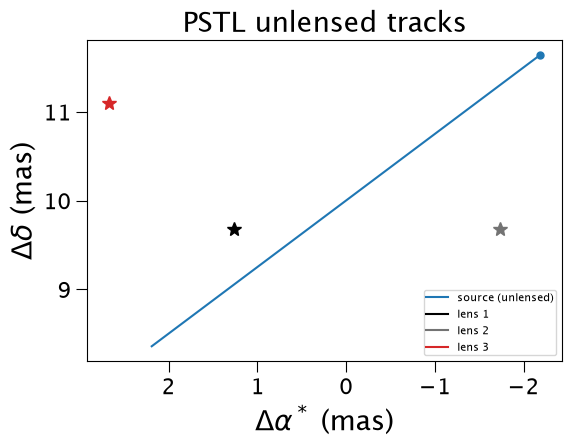

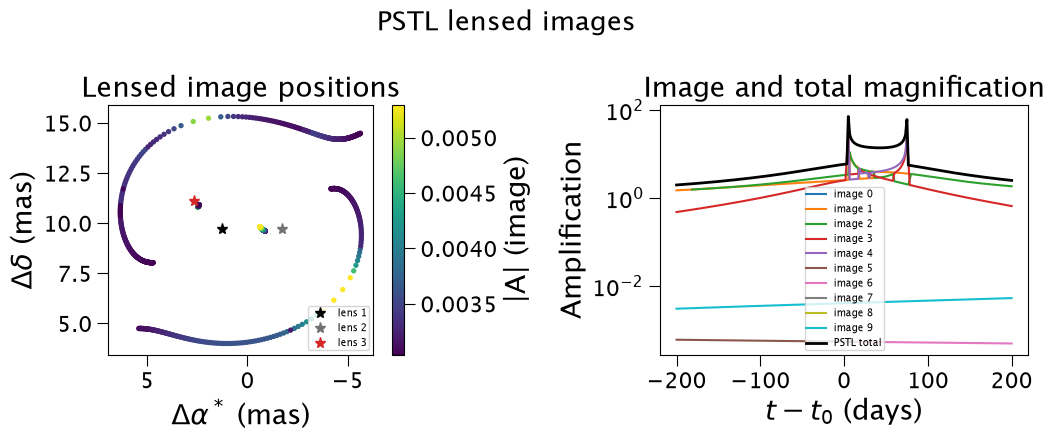

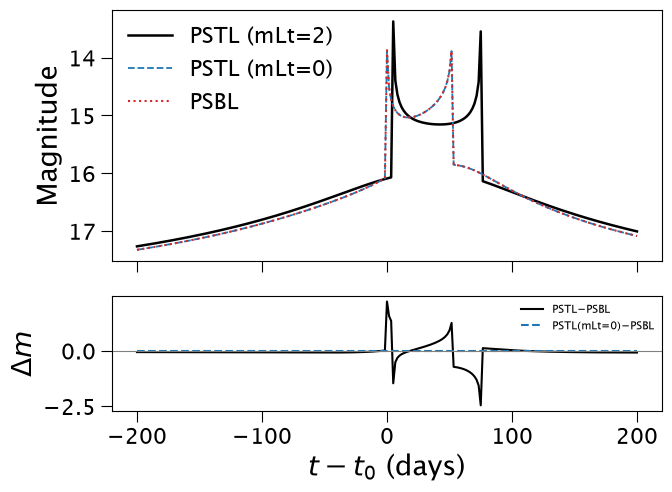

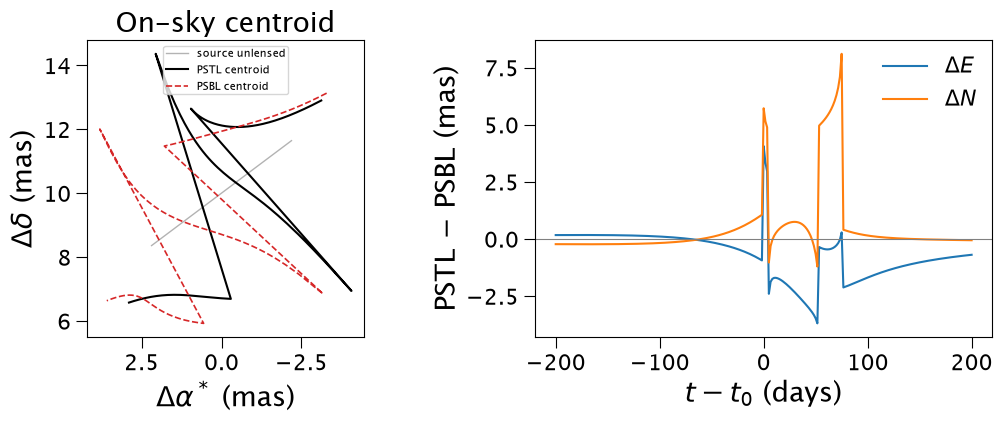

In [9]:
plot_unlensed(pstl, t, 'PSTL unlensed tracks')
plot_lensed_images(pstl, t, 'PSTL lensed images')
plot_photometry(pstl, psbl, pstl0, t)
plot_astrometry(pstl, psbl, t)

## Caustics, critical curves, and magnification map

`plot_models.gen_and_plot_caustics_and_critical_curves` and
`plot_models.get_magnification_map` work for PSTL (and PSBL).
Caustics are in Einstein radii of the 1–2 pair; the map is in arcsec.

findfont: Failed to find font weight normal, now using 500.


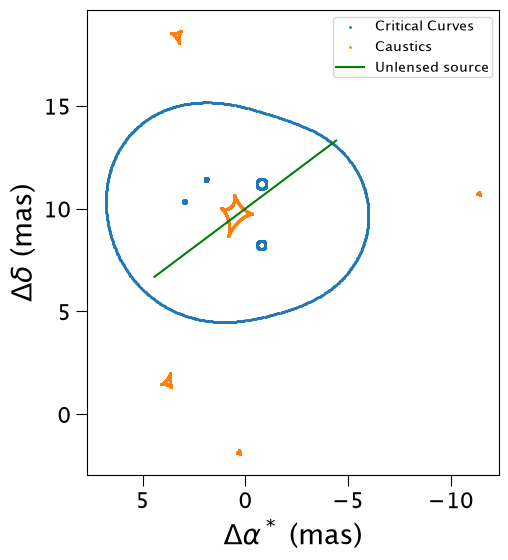

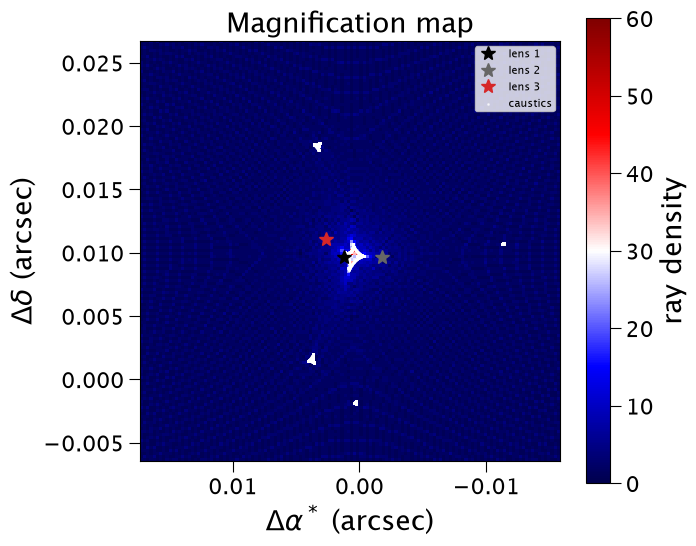

In [10]:
ax_c = plot_models.gen_and_plot_caustics_and_critical_curves(
    pstl, show=True, N_pts=400)
ax_m = plot_models.get_magnification_map(
    pstl, bins=250, N_pts=300, show=True)